# Forecasting Next-Hour Electricity Consumption in Laayoune, Morocco

#### Student name(s): Your Name Here

**Abstract.** This project builds and evaluates machine-learning models that forecast the total electricity consumption of the city of Laayoune (Morocco) **one hour ahead**. The data are 10-minute readings from five distribution zones (September 2022 to May 2024). After exploratory data analysis (tables and eight charts), the data are cleaned (duplicate timestamps from daylight-saving changes and outage rows with zero readings), aggregated to hourly values, and turned into lag, rolling-average and calendar features. Two naive baselines and three scikit-learn models (Ridge regression, Random Forest, Histogram Gradient Boosting) are compared on a chronological hold-out test set using MAE, RMSE, R² and MAPE. The tuned Random Forest performed best (test MAE 16.5, R² 0.946), reducing the error by about 64% compared with the "same as the previous hour" baseline.

## Table of Content

[Problem](#problem)   
[Data Understanding](#data_understanding)   
[Data Preparation](#data_preparation)   
[Modeling](#modeling)   
[Evaluation](#evaluation)   
[References](#references)

## Problem <a class="anchor" id="problem"></a>

Electricity utilities must balance supply and demand continuously. Forecasting demand a short time ahead helps with generation scheduling, avoiding overload of the distribution network, and reducing cost.

**Question:** *Given the consumption history of Laayoune's five distribution zones up to hour **t**, how accurately can we predict the total consumption during hour **t+1**?*

Sub-questions:
1. What daily, weekly and seasonal patterns exist in the data?
2. Do machine-learning models beat simple baselines ("same as now" and "same hour yesterday")?
3. Which features matter most for the forecast?

This is a **supervised regression** problem on a time series, so the evaluation must respect time order (no random shuffling).

### Step 0: Set up the environment
We import the libraries, fix a random seed for reproducibility, and set a plotting style. Every code cell in this notebook prints something so the output can be checked.

In [1]:
# Step 0: imports and global settings
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error)

warnings.filterwarnings("ignore")      # keep the printout clean
RANDOM_STATE = 42                      # reproducibility
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("Setup complete.")

pandas 3.0.3 | numpy 2.4.6 | scikit-learn 1.9.0
Setup complete.


## Data Understanding<a class="anchor" id="data_understanding"></a>

**Data set.** The file `Data_Morocco.xlsx` (placed in the same folder as this notebook) contains electricity-consumption readings for four Moroccan locations, one Excel sheet each. Each row is a timestamp and one column per distribution *zone*. The original source of the file: *[add the original download URL here]*. The consumption unit is not documented in the file, so values are treated as relative consumption units.

We use the **Laayoune** sheet (5 zones and about 88,900 ten-minute readings) as the main data set.

### Step 1: Overview of all sheets
First we look at what each sheet contains.

In [6]:
# Step 1: read every sheet and summarise it
DATA_FILE = "DataMorocco.xlsx"
sheets = pd.read_excel(DATA_FILE, sheet_name=None)   # dict: sheet name -> DataFrame

overview = pd.DataFrame([{
    "sheet": name,
    "rows": df.shape[0],
    "zones": df.shape[1] - 1,
    "start": df["DateTime"].min(),
    "end": df["DateTime"].max(),
    "median step": df["DateTime"].diff().median(),
} for name, df in sheets.items()])
print(overview.to_string(index=False))

      sheet  rows  zones               start                 end     median step
   Laayoune 88890      5 2022-09-14 17:10:00 2024-05-24 00:00:00 0 days 00:10:00
   Boujdour 88890      3 2022-09-14 17:10:00 2024-05-24 00:00:00 0 days 00:10:00
Foum eloued 88890      7 2022-09-14 17:10:00 2024-05-24 00:00:00 0 days 00:10:00
  Marrakech 17501      2 2023-01-09 00:00:00 2024-01-08 23:30:00 0 days 00:30:00


Laayoune, Boujdour and Foum eloued share the same 10-minute timeline (88,890 rows, Sept 2022 to May 2024); Marrakech has 30-minute readings over one year (17,501 rows). We continue with Laayoune.

### Step 2: First look at the Laayoune data

In [7]:
# Step 2: first rows, data types and basic statistics
raw = sheets["Laayoune"].copy()
zones = [c for c in raw.columns if c.startswith("zone")]

print("Shape:", raw.shape)
print("\nFirst 5 rows:")
print(raw.head().to_string(index=False))
print("\nData types:")
print(raw.dtypes.to_string())
print("\nSummary statistics:")
print(raw[zones].describe().T.round(2).to_string())

Shape: (88890, 6)

First 5 rows:
           DateTime     zone1      zone2      zone3      zone4      zone5
2022-09-14 17:10:00 73.536915 120.920183 160.982021 122.236644 102.922162
2022-09-14 17:20:00 74.403119 122.179697 159.403248 119.727278 101.747520
2022-09-14 17:30:00 77.893555 124.701734 159.969683 118.508081 102.074112
2022-09-14 17:40:00 78.317958 126.731194 161.969315 118.571429 102.911361
2022-09-14 17:50:00 81.334845 125.741697 163.189366 120.688295 102.546117

Data types:
DateTime    datetime64[us]
zone1              float64
zone2              float64
zone3              float64
zone4              float64
zone5              float64

Summary statistics:
         count    mean    std  min     25%     50%     75%     max
zone1  88890.0   65.53  18.91  0.0   50.24   64.50   78.02  132.67
zone2  88890.0  109.90  33.78  0.0   81.87  109.58  131.52  533.02
zone3  88890.0  151.44  40.74  0.0  115.99  155.29  184.97  715.86
zone4  88890.0  113.58  26.15  0.0   92.30  115.74  132.94 

All five zone columns are numeric with no missing values (`NaN`). However, the minimum of every zone is 0, which is suspicious, and zone 2 and zone 3 have maximum values far above their means. We check data quality next.

### Step 3: Data quality checks
We check (a) duplicated timestamps, (b) irregular time steps (gaps), and (c) rows where zones read exactly 0 (likely outages or logging failures).

In [8]:
# Step 3: data-quality table
raw = raw.sort_values("DateTime").reset_index(drop=True)
step = raw["DateTime"].diff()

n_dup = raw["DateTime"].duplicated().sum()
n_gap = (step > pd.Timedelta("10min")).sum()
n_back = (step < pd.Timedelta(0)).sum()
all_zero = raw[zones].eq(0).all(axis=1)
any_zero = raw[zones].eq(0).any(axis=1)

quality = pd.DataFrame({
    "check": ["Missing values", "Duplicated timestamps", "Gaps longer than 10 min",
              "Timestamps going backwards", "Rows with all zones = 0", "Rows with any zone = 0"],
    "count": [int(raw.isna().sum().sum()), int(n_dup), int(n_gap), int(n_back),
              int(all_zero.sum()), int(any_zero.sum())]
})
print(quality.to_string(index=False))

print("\nIrregular time steps (dates):")
print(raw.loc[(step != pd.Timedelta("10min")) & step.notna(), "DateTime"].dt.date.value_counts().sort_index().to_string())
print("\nDays with the most all-zero rows:")
print(raw.loc[all_zero, "DateTime"].dt.date.value_counts().head(4).to_string())
print("\nDays with the most rows where at least one zone is 0:")
print(raw.loc[any_zero, "DateTime"].dt.date.value_counts().head(5).to_string())

                     check  count
            Missing values      0
     Duplicated timestamps     12
   Gaps longer than 10 min      2
Timestamps going backwards      0
   Rows with all zones = 0     88
    Rows with any zone = 0    582

Irregular time steps (dates):
DateTime
2022-10-30    6
2023-04-23    1
2023-10-29    6
2024-04-14    1

Days with the most all-zero rows:
DateTime
2023-01-29    65
2023-01-28    17
2022-09-26     5
2024-02-05     1

Days with the most rows where at least one zone is 0:
DateTime
2024-04-01    144
2024-03-31     77
2023-01-29     65
2022-10-24     57
2024-04-02     42


Findings:
* The duplicated timestamps and gaps all happen on the **daylight-saving change dates** (late October and April), so they are clock effects and not real data problems.
* **88 rows have all five zones at exactly 0** (for example 28 to 29 January 2023), which is not real zero demand for a city; these look like outages or logging failures.
* A further **494 rows have only some zones at 0** (for example 31 March to 2 April 2024), which looks like a zone-level outage. Such zeros would make the total too low.
* Because zeros are not real demand, every row with **at least one zero zone** (582 rows, 0.65%) will be treated as missing in Data Preparation.

### Step 4: Exploratory Data Analysis (EDA)
For the charts below we mask the rows with a zero reading (set them to `NaN`) so that they do not distort the averages. We also add a `total` column (sum of the five zones) and calendar columns.

In [9]:
# Step 4a: build an EDA copy with outage rows masked and calendar columns added
eda = raw.copy()
eda.loc[any_zero, zones] = np.nan                 # mask outage rows for the EDA charts
eda["total"] = eda[zones].sum(axis=1, min_count=5)
eda["hour"] = eda["DateTime"].dt.hour
eda["dayofweek"] = eda["DateTime"].dt.dayofweek   # 0 = Monday
eda["day_name"] = eda["DateTime"].dt.day_name()
eda["month"] = eda["DateTime"].dt.to_period("M")

# Table 1: statistics per zone and share of total consumption
zone_tbl = eda[zones].agg(["mean", "std", "min", "max"]).T
zone_tbl["share of total (%)"] = 100 * zone_tbl["mean"] / zone_tbl["mean"].sum()
print("Table 1 - statistics per zone (outages masked):")
print(zone_tbl.round(2).to_string())
print("\nTotal consumption statistics:")
print(eda["total"].describe().round(2).to_string())

Table 1 - statistics per zone (outages masked):
         mean    std   min     max  share of total (%)
zone1   65.61  18.81  0.56  132.67               11.66
zone2  110.19  33.48  0.09  533.02               19.58
zone3  152.14  39.60  0.00  715.86               27.03
zone4  114.11  25.05  0.11  255.25               20.27
zone5  120.84  32.89  0.11  326.85               21.47

Total consumption statistics:
count    88308.00
mean       562.89
std        128.78
min         71.83
25%        450.10
50%        565.99
75%        666.28
max       1316.84


Zone 3 is the largest consumer (about 27% of the total) and zone 1 the smallest (about 12%). Zone 3 has the highest standard deviation, and zones 2 and 3 have extreme maximum values (533 and 716) far above their means.

**Chart 1 – Consumption over time.** The raw data (outages *not* masked) are shown as daily averages to reveal long-term trends and the outage days.

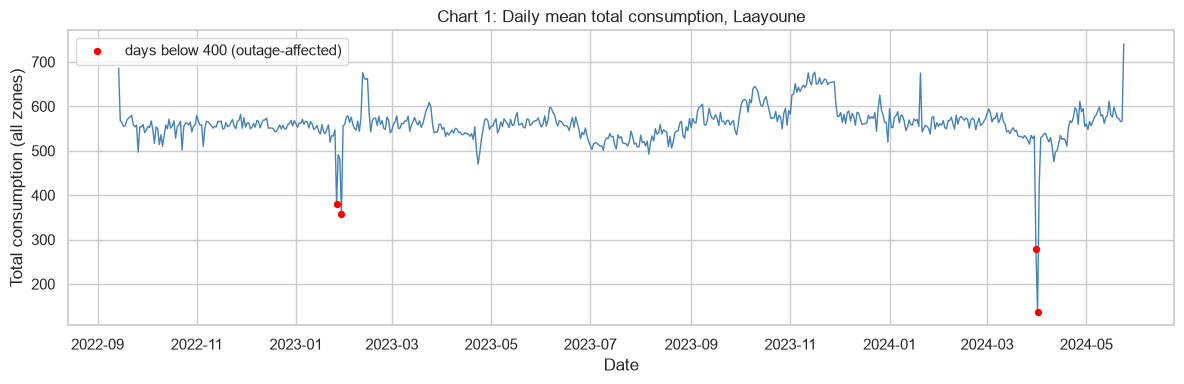

Days flagged as outage-affected: 4
Daily mean range (excluding flagged days): 420.2 to 740.6


In [10]:
# Chart 1: daily mean of total consumption, raw data (outages included)
raw_total = raw.set_index("DateTime")[zones].sum(axis=1)
daily = raw_total.resample("D").mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.values, lw=1, color="steelblue")
low = daily[daily < 400]
ax.scatter(low.index, low.values, color="red", s=18, zorder=3, label="days below 400 (outage-affected)")
ax.set_title("Chart 1: Daily mean total consumption, Laayoune")
ax.set_xlabel("Date"); ax.set_ylabel("Total consumption (all zones)")
ax.legend()
plt.tight_layout(); plt.show()
print("Days flagged as outage-affected:", len(low))
print("Daily mean range (excluding flagged days): %.1f to %.1f" % (daily[daily >= 400].min(), daily[daily >= 400].max()))

Daily mean consumption moves around an overall mean of about 560 units, with a visible seasonal swing over the year, plus a few days with sharp drops (red points) caused by outages.

**Chart 2 – Distribution.** Histogram of the total and boxplots per zone.

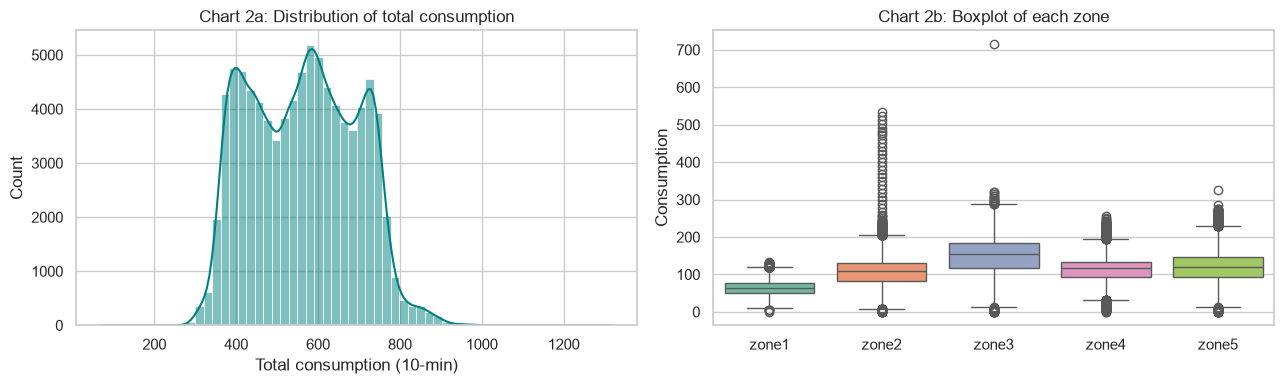

Skewness of total: 0.13
Share of readings above 800: 1.91%


In [11]:
# Chart 2: distribution of total consumption and of each zone
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(eda["total"].dropna(), bins=60, kde=True, ax=axes[0], color="teal")
axes[0].set_title("Chart 2a: Distribution of total consumption")
axes[0].set_xlabel("Total consumption (10-min)")

sns.boxplot(data=eda[zones], ax=axes[1], palette="Set2")
axes[1].set_title("Chart 2b: Boxplot of each zone")
axes[1].set_ylabel("Consumption")
plt.tight_layout(); plt.show()
print("Skewness of total: %.2f" % eda["total"].skew())
print("Share of readings above 800: %.2f%%" % (100 * (eda["total"] > 800).mean()))

The total is roughly symmetric and bell-shaped (skewness close to 0), and only about 2% of readings are above 800. The boxplots show high outliers in zones 2, 3 and 5; these are the peak periods and are kept, but they are why tree-based models and robust metrics (MAE) are attractive.

**Chart 3 – Daily profile.** Average consumption by hour of day for each zone.

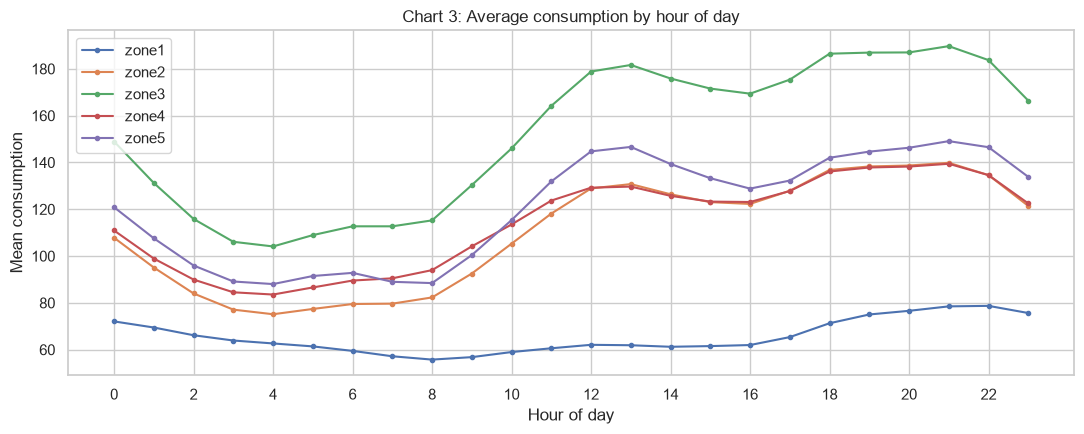

Hour of peak total consumption: 21
Hour of lowest total consumption: 4
Peak hour of each zone: {'zone1': 22, 'zone2': 21, 'zone3': 21, 'zone4': 21, 'zone5': 21}


In [13]:
# Chart 3: average consumption by hour of day, one line per zone
hourly_profile = eda.groupby("hour")[zones].mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
hourly_profile.plot(ax=ax, marker="o", ms=3)
ax.set_title("Chart 3: Average consumption by hour of day")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Mean consumption")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()
print("Hour of peak total consumption:", int(eda.groupby("hour")["total"].mean().idxmax()))
print("Hour of lowest total consumption:", int(eda.groupby("hour")["total"].mean().idxmin()))
print("Peak hour of each zone:", hourly_profile.idxmax().to_dict())

There is a strong daily cycle: total demand is lowest around 4 a.m. and peaks around 9 p.m. Zones 2 to 5 peak at 9 p.m. and zone 1 at 10 p.m.

**Chart 4 – Weekly pattern.**

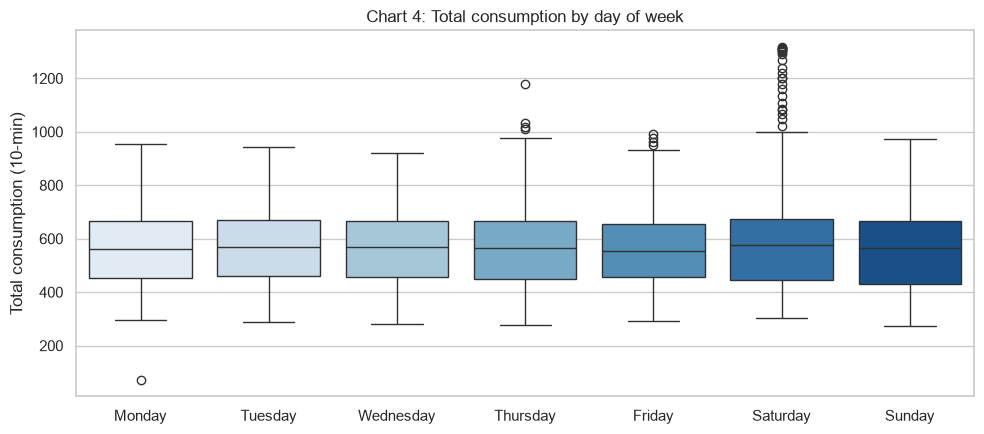

day_name
Monday       561.4
Tuesday      567.1
Wednesday    566.1
Thursday     562.4
Friday       558.2
Saturday     566.4
Sunday       558.5


In [14]:
# Chart 4: boxplot of total consumption by day of week
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=eda, x="day_name", y="total", order=order, ax=ax, palette="Blues")
ax.set_title("Chart 4: Total consumption by day of week")
ax.set_xlabel(""); ax.set_ylabel("Total consumption (10-min)")
plt.tight_layout(); plt.show()
print(eda.groupby("day_name")["total"].mean().reindex(order).round(1).to_string())

Weekday means only differ by about 10 units out of about 560, which is small compared with the within-day variation, so the day of week is a much weaker signal than the hour of day.

**Chart 5 – Seasonal pattern.**

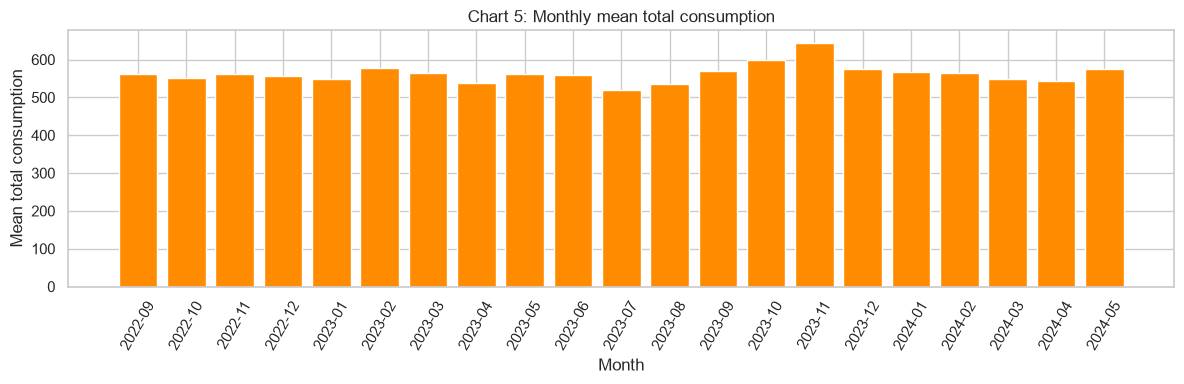

Highest month: 2023-11 644.7
Lowest month:  2023-07 519.4


In [15]:
# Chart 5: monthly mean of total consumption
monthly = eda.groupby("month")["total"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(monthly.index.astype(str), monthly.values, color="darkorange")
ax.set_title("Chart 5: Monthly mean total consumption")
ax.set_xlabel("Month"); ax.set_ylabel("Mean total consumption")
plt.xticks(rotation=60)
plt.tight_layout(); plt.show()
print("Highest month:", str(monthly.idxmax()), round(monthly.max(), 1))
print("Lowest month: ", str(monthly.idxmin()), round(monthly.min(), 1))

Monthly averages vary from about 519 (July 2023) to about 645 (November 2023), a spread of roughly 125 units, so there is a clear seasonal component and a month feature may help. The first and last months are partial, so read them with care.

**Chart 6 – Correlation between zones.**

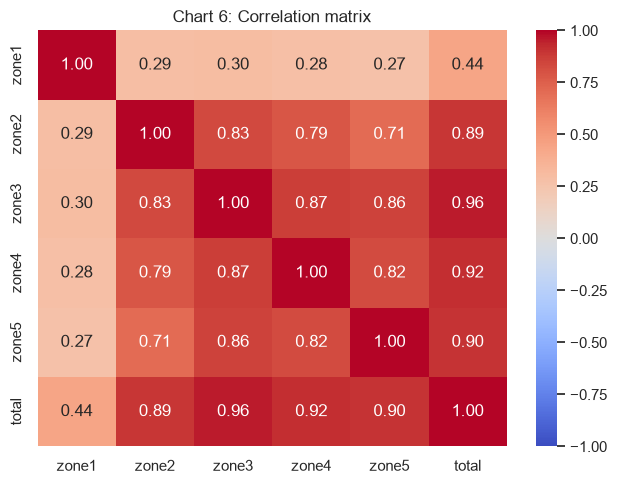

       zone1  zone2  zone3  zone4  zone5  total
zone1   1.00   0.29   0.30   0.28   0.27   0.44
zone2   0.29   1.00   0.83   0.79   0.71   0.89
zone3   0.30   0.83   1.00   0.87   0.86   0.96
zone4   0.28   0.79   0.87   1.00   0.82   0.92
zone5   0.27   0.71   0.86   0.82   1.00   0.90
total   0.44   0.89   0.96   0.92   0.90   1.00


In [16]:
# Chart 6: correlation heatmap of the zones and the total
corr = eda[zones + ["total"]].corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Chart 6: Correlation matrix")
plt.tight_layout(); plt.show()
print(corr.round(2).to_string())

Zones 2 to 5 are strongly correlated with each other and with the total, while zone 1 is only weakly correlated with the others (about 0.3), so it carries different information. Zone 3 is the best single proxy for the total.

**Chart 7 – Hour × weekday heatmap.**

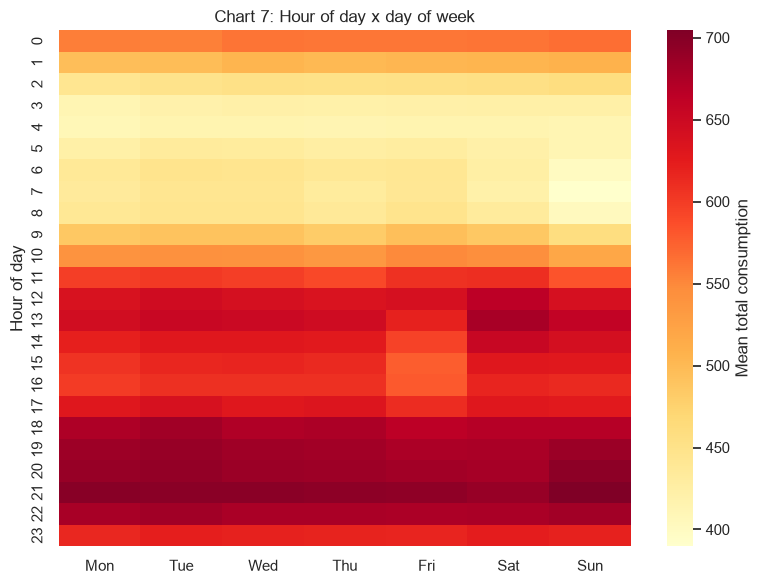

Max cell: 704.3 | Min cell: 389.6


In [18]:
# Chart 7: mean total consumption by hour of day and day of week
pivot = eda.pivot_table(index="hour", columns="dayofweek", values="total", aggfunc="mean")
pivot.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pivot, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Mean total consumption"})
ax.set_title("Chart 7: Hour of day x day of week")
ax.set_ylabel("Hour of day")
plt.tight_layout(); plt.show()
print("Max cell: %.1f | Min cell: %.1f" % (pivot.values.max(), pivot.values.min()))

**Chart 8 – Autocorrelation.** How strongly is consumption related to its own past? This helps us pick lag features.

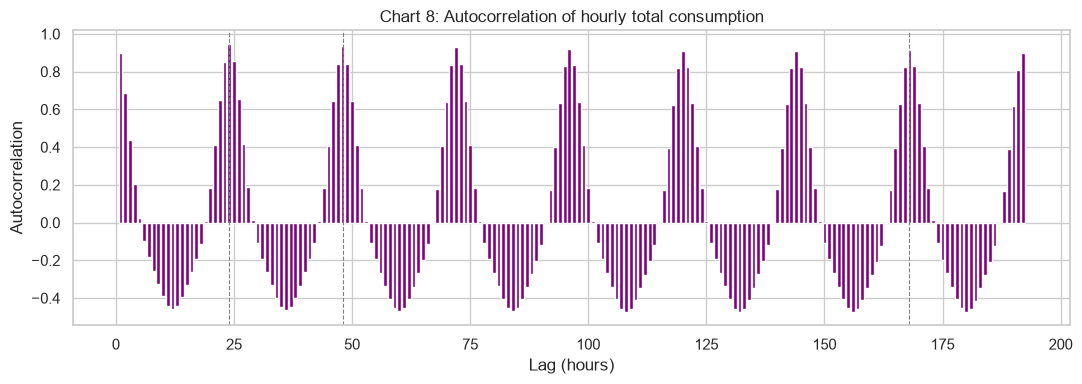

ACF at lag 1h: 0.899 | 24h: 0.947 | 168h: 0.914


In [19]:
# Chart 8: autocorrelation of hourly total up to 8 days (192 hours)
hourly_total = eda.set_index("DateTime")["total"].resample("1h").mean().interpolate(limit=3)
lags = np.arange(1, 193)
acf = [hourly_total.autocorr(lag=int(l)) for l in lags]

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(lags, acf, color="purple", width=0.8)
ax.set_title("Chart 8: Autocorrelation of hourly total consumption")
ax.set_xlabel("Lag (hours)"); ax.set_ylabel("Autocorrelation")
for h in (24, 48, 168):
    ax.axvline(h, color="gray", ls="--", lw=0.8)
plt.tight_layout(); plt.show()
print("ACF at lag 1h: %.3f | 24h: %.3f | 168h: %.3f" % (acf[0], acf[23], acf[167]))

Autocorrelation is about 0.9 at 1 hour and stays high at 24 hours, with repeating peaks at multiples of 24 hours, which confirms the daily cycle. This supports using recent lags and the value at the same hour of the previous day.

**EDA summary:** (1) strong daily cycle, (2) weak weekly and mild seasonal effects, (3) zones are positively correlated (zone 1 least), (4) outage rows with zero readings must be handled, (5) daylight-saving changes create duplicate and missing timestamps.

## Data Preparation<a class="anchor" id="data_preparation"></a>

Planned transformations:
1. **Fix timestamps:** average duplicated timestamps (autumn clock change) and place the data on a regular 10-minute grid (spring clock change creates a one-hour gap).
2. **Outages:** replace every row in which at least one zone reads 0 by `NaN` (missing).
3. **Aggregate to hourly** means to reduce noise and make a one-hour-ahead target meaningful.
4. **Fill short gaps** (up to 3 hours) by time interpolation; longer gaps stay missing and their rows are dropped.
5. **Feature engineering:** lag features, a 24-hour rolling mean, zone values, and calendar features (cyclic encoding for the hour).
6. **Target:** total consumption of the **next** hour.
7. **Chronological split:** first 80% of time for training, last 20% for testing.

### Step 5: Clean timestamps and mask outages

In [20]:
# Step 5: clean the raw 10-minute data
clean = raw.copy()
clean.loc[any_zero, zones] = np.nan                     # outages (any zero zone) -> missing

before = len(clean)
clean = clean.groupby("DateTime", as_index=True)[zones].mean()   # average duplicated timestamps
clean = clean.asfreq("10min")                                     # regular 10-minute grid (gaps -> NaN)

print("Rows before:", before, "| rows after regular grid:", len(clean))
print("Missing 10-min readings after cleaning:", int(clean.isna().any(axis=1).sum()))
print("Grid check - unique steps:", clean.index.to_series().diff().dropna().unique())

Rows before: 88890 | rows after regular grid: 88890
Missing 10-min readings after cleaning: 594
Grid check - unique steps: <TimedeltaArray>
['0 days 00:10:00']
Length: 1, dtype: timedelta64[us]


### Step 6: Aggregate to hourly values and fill short gaps

In [21]:
# Step 6: hourly means, short-gap interpolation, and total consumption
hourly = clean.resample("1h").mean()                    # hourly mean per zone
n_missing_before = int(hourly.isna().any(axis=1).sum())
hourly = hourly.interpolate(method="time", limit=3)     # fill gaps of up to 3 hours
n_missing_after = int(hourly.isna().any(axis=1).sum())
hourly["total"] = hourly[zones].sum(axis=1, min_count=len(zones))

print("Hourly rows:", len(hourly))
print("Hours with missing zone values before filling:", n_missing_before)
print("Hours still missing after filling (gaps > 3 h):", n_missing_after)
print(hourly.head(3).round(1).to_string())

Hourly rows: 14816
Hours with missing zone values before filling: 80
Hours still missing after filling (gaps > 3 h): 56
                     zone1  zone2  zone3  zone4  zone5  total
DateTime                                                     
2022-09-14 17:00:00   77.1  124.1  161.1  119.9  102.4  584.6
2022-09-14 18:00:00   88.7  136.0  171.0  123.0  105.9  624.5
2022-09-14 19:00:00  107.0  162.6  201.1  143.8  135.4  749.8


### Step 7: Feature engineering and target
All features at row **t** use only information available up to hour t. The target is the total at **t+1**. The calendar features describe the hour being predicted (t+1).

| Feature | Meaning |
|---|---|
| `total_t`, `total_t-1`, `total_t-2`, `total_t-3` | most recent hourly totals |
| `same_hour_yesterday` | total at the same clock hour as the target, 24 h earlier (t−23) |
| `same_hour_last_week` | total at the same hour and weekday as the target, one week earlier (t−167) |
| `rolling_mean_24h` | mean of the last 24 hourly totals |
| `zone1`…`zone5` | zone values at hour t |
| `hour_sin`, `hour_cos`, `dayofweek`, `is_weekend`, `month` | calendar information of the target hour |

In [22]:
# Step 7: build the feature matrix X and the target y
feat = pd.DataFrame(index=hourly.index)
feat["total_t"]    = hourly["total"]
feat["total_t-1"]  = hourly["total"].shift(1)
feat["total_t-2"]  = hourly["total"].shift(2)
feat["total_t-3"]  = hourly["total"].shift(3)
feat["same_hour_yesterday"] = hourly["total"].shift(23)    # value at (t+1) - 24h
feat["same_hour_last_week"] = hourly["total"].shift(167)   # value at (t+1) - 168h
feat["rolling_mean_24h"]    = hourly["total"].rolling(24).mean()
for z in zones:
    feat[z] = hourly[z]

target_time = feat.index + pd.Timedelta(hours=1)           # the hour we are predicting
feat["hour_sin"]   = np.sin(2 * np.pi * target_time.hour / 24)
feat["hour_cos"]   = np.cos(2 * np.pi * target_time.hour / 24)
feat["dayofweek"]  = target_time.dayofweek
feat["is_weekend"] = (target_time.dayofweek >= 5).astype(int)
feat["month"]      = target_time.month

feat["target"] = hourly["total"].shift(-1)                 # total of the next hour

model_df = feat.dropna()
X = model_df.drop(columns="target")
y = model_df["target"]
print("Rows dropped because of missing values:", len(feat) - len(model_df))
print("X shape:", X.shape, "| y shape:", y.shape)
print("Feature list:", list(X.columns))
print(X.head(3).round(2).to_string())

Rows dropped because of missing values: 352
X shape: (14464, 17) | y shape: (14464,)
Feature list: ['total_t', 'total_t-1', 'total_t-2', 'total_t-3', 'same_hour_yesterday', 'same_hour_last_week', 'rolling_mean_24h', 'zone1', 'zone2', 'zone3', 'zone4', 'zone5', 'hour_sin', 'hour_cos', 'dayofweek', 'is_weekend', 'month']
                     total_t  total_t-1  total_t-2  total_t-3  same_hour_yesterday  same_hour_last_week  rolling_mean_24h  zone1   zone2   zone3   zone4   zone5  hour_sin  hour_cos  dayofweek  is_weekend  month
DateTime                                                                                                                                                                                                          
2022-09-21 16:00:00   572.85     570.85     616.16     692.68               595.73               584.64            575.11  75.52  119.19  154.71  119.86  103.56     -0.97     -0.26          2           0      9
2022-09-21 17:00:00   592.94     572.85     57

### Step 8: Chronological train/test split
Time-series data must not be shuffled: the model is trained on the past and tested on the future.

In [23]:
# Step 8: first 80% of time for training, last 20% for testing
split = int(len(model_df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train:", X_train.shape, "from", X_train.index.min(), "to", X_train.index.max())
print("Test: ", X_test.shape,  "from", X_test.index.min(),  "to", X_test.index.max())
print("Mean target - train: %.1f | test: %.1f" % (y_train.mean(), y_test.mean()))

Train: (11571, 17) from 2022-09-21 16:00:00 to 2024-01-20 02:00:00
Test:  (2893, 17) from 2024-01-20 03:00:00 to 2024-05-23 23:00:00
Mean target - train: 564.0 | test: 558.5


## Modeling<a class="anchor" id="modeling"></a>

**Models.**
* **Baseline 1 – Persistence:** predict that next hour equals the current hour (`total_t`).
* **Baseline 2 – Seasonal naive:** predict next hour equals the same hour yesterday (`same_hour_yesterday`).
* **Ridge regression** (with standardised features): a regularised linear model; fast and interpretable, a good check of how much is linear.
* **Random Forest:** an ensemble of decision trees; captures non-linear effects and interactions and is robust to outliers.
* **Histogram Gradient Boosting:** a boosted-tree model that is usually very accurate on tabular data.

**Tuning.** Hyper-parameters are chosen with `GridSearchCV` using `TimeSeriesSplit` (4 folds, each validating on a later period than it trains on) and the **mean absolute error** as the score. The test set is not used for tuning.

### Step 9: Define the metrics and evaluate the baselines

In [25]:
# Step 9: metric helper and the two naive baselines
def evaluate(y_true, y_pred):
    # returns MAE, RMSE, R2 and MAPE (%) for a set of predictions
    return {
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2":   r2_score(y_true, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
    }

results = {}
results["Persistence (t)"]          = evaluate(y_test, X_test["total_t"])
results["Seasonal naive (24 h)"]    = evaluate(y_test, X_test["same_hour_yesterday"])
print(pd.DataFrame(results).T.round(3).to_string())

                          MAE    RMSE     R2  MAPE (%)
Persistence (t)        46.008  58.034  0.785     8.409
Seasonal naive (24 h)  25.916  47.022  0.859     4.672


### Step 10: Ridge regression

In [26]:
# Step 10: Ridge with scaling, tuned over alpha
tscv = TimeSeriesSplit(n_splits=4)

ridge_pipe = make_pipeline(StandardScaler(), Ridge(random_state=RANDOM_STATE))
ridge_grid = {"ridge__alpha": [0.01, 0.1, 1, 10, 100]}
ridge_cv = GridSearchCV(ridge_pipe, ridge_grid, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1)
ridge_cv.fit(X_train, y_train)

print("Best parameters:", ridge_cv.best_params_)
print("Best CV MAE: %.3f" % -ridge_cv.best_score_)

Best parameters: {'ridge__alpha': 0.01}
Best CV MAE: 20.607


### Step 11: Random Forest

In [29]:
# Step 11: Random Forest tuned over depth and leaf size
rf = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_grid = {"max_depth": [10, 20, None], "min_samples_leaf": [1, 5, 10]}
rf_cv = GridSearchCV(rf, rf_grid, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=1)
rf_cv.fit(X_train, y_train)

print("Best parameters:", rf_cv.best_params_)
print("Best CV MAE: %.3f" % -rf_cv.best_score_)

Best parameters: {'max_depth': None, 'min_samples_leaf': 1}
Best CV MAE: 19.668


### Step 12: Histogram Gradient Boosting

In [30]:
# Step 12: Histogram Gradient Boosting tuned over learning rate, iterations and depth
hgb = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
hgb_grid = {"learning_rate": [0.03, 0.1], "max_iter": [200, 500], "max_depth": [None, 6]}
hgb_cv = GridSearchCV(hgb, hgb_grid, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1)
hgb_cv.fit(X_train, y_train)

print("Best parameters:", hgb_cv.best_params_)
print("Best CV MAE: %.3f" % -hgb_cv.best_score_)

Best parameters: {'learning_rate': 0.03, 'max_depth': None, 'max_iter': 200}
Best CV MAE: 20.048


## Evaluation<a class="anchor" id="evaluation"></a>

### Step 13: Compare all models on the hold-out test set
Each tuned model was refitted on the full training set by `GridSearchCV`. Now we score them once on the unseen test period.

In [31]:
# Step 13: test-set metrics for all models
tuned = {
    "Ridge": ridge_cv,
    "Random Forest": rf_cv,
    "Hist Gradient Boosting": hgb_cv,
}
preds = {}
for name, model in tuned.items():
    preds[name] = model.predict(X_test)
    results[name] = evaluate(y_test, preds[name])

results_df = pd.DataFrame(results).T.sort_values("MAE")
cv_mae = {n: -m.best_score_ for n, m in tuned.items()}
results_df["CV MAE (train)"] = pd.Series(cv_mae)
print("Table 2 - test-set results (sorted by MAE):")
print(results_df.round(3).to_string())

best_name = results_df.drop(index=["Persistence (t)", "Seasonal naive (24 h)"]).index[0]
print("\nBest model on the test set:", best_name)

Table 2 - test-set results (sorted by MAE):
                           MAE    RMSE     R2  MAPE (%)  CV MAE (train)
Random Forest           16.528  29.209  0.946     3.016          19.668
Hist Gradient Boosting  16.903  28.810  0.947     3.107          20.048
Ridge                   20.999  31.751  0.936     3.826          20.607
Seasonal naive (24 h)   25.916  47.022  0.859     4.672             NaN
Persistence (t)         46.008  58.034  0.785     8.409             NaN

Best model on the test set: Random Forest


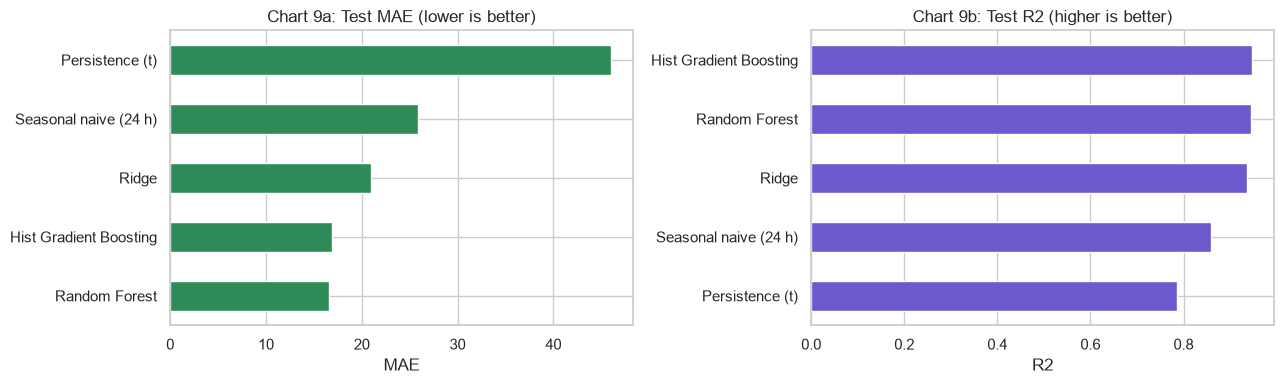

Improvement of best model over persistence: 64.1% lower MAE


In [32]:
# Chart 9: MAE and R2 of every model
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results_df["MAE"].sort_values().plot.barh(ax=axes[0], color="seagreen")
axes[0].set_title("Chart 9a: Test MAE (lower is better)")
axes[0].set_xlabel("MAE")
results_df["R2"].sort_values().plot.barh(ax=axes[1], color="slateblue")
axes[1].set_title("Chart 9b: Test R2 (higher is better)")
axes[1].set_xlabel("R2")
plt.tight_layout(); plt.show()
print("Improvement of best model over persistence: %.1f%% lower MAE" %
      (100 * (1 - results_df.loc[best_name, "MAE"] / results_df.loc["Persistence (t)", "MAE"])))

### Step 14: Predictions versus actual values
We plot the last 7 days of the test period, then actual-versus-predicted for all test points.

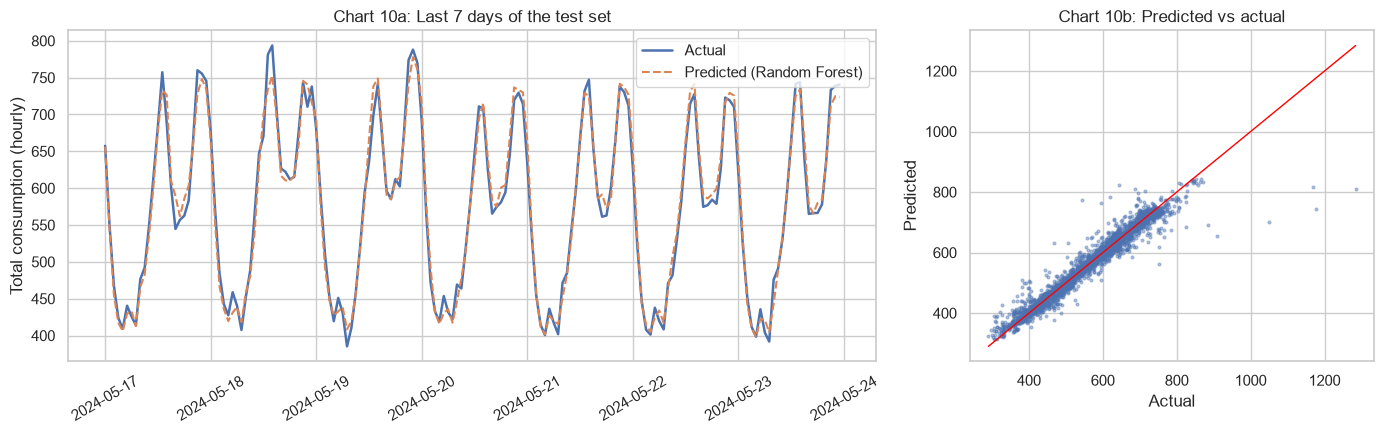

Correlation between predicted and actual: 0.9724


In [33]:
# Chart 10: last 7 days of the test set and scatter plot, best model
best_model = tuned[best_name]
y_pred = preds[best_name]
last = slice(-168, None)                                   # last 168 hours

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(y_test.index[last], y_test.values[last], label="Actual", lw=1.8)
axes[0].plot(y_test.index[last], y_pred[last], label="Predicted (%s)" % best_name, lw=1.5, ls="--")
axes[0].set_title("Chart 10a: Last 7 days of the test set")
axes[0].set_ylabel("Total consumption (hourly)"); axes[0].legend()
axes[0].tick_params(axis="x", rotation=30)

axes[1].scatter(y_test, y_pred, s=4, alpha=0.4)
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, color="red", lw=1)
axes[1].set_title("Chart 10b: Predicted vs actual")
axes[1].set_xlabel("Actual"); axes[1].set_ylabel("Predicted")
plt.tight_layout(); plt.show()
print("Correlation between predicted and actual: %.4f" % np.corrcoef(y_test, y_pred)[0, 1])

### Step 15: Residual analysis
Residuals (actual − predicted) should be centred on zero. We also check whether errors depend on the hour of day.

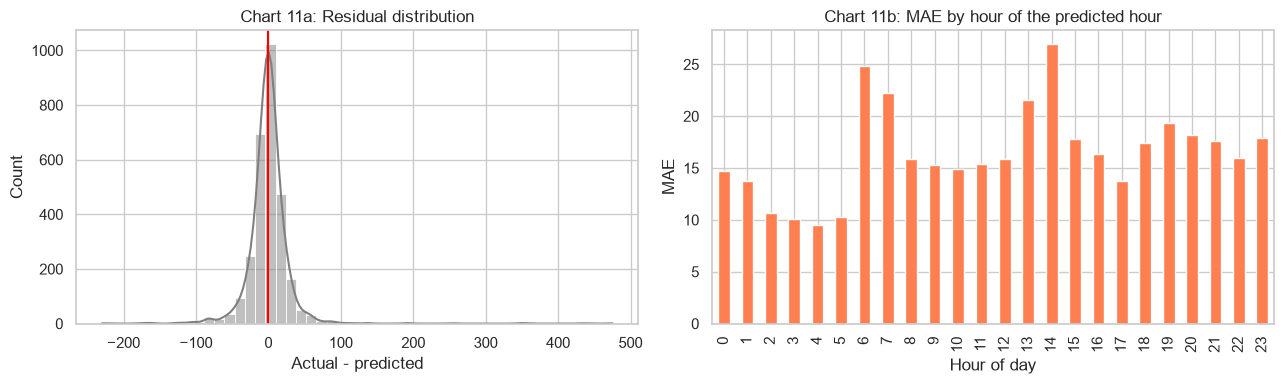

Residual mean: -0.21 | std: 29.21
Hardest hour: 14 (MAE 26.92) | easiest hour: 4 (MAE 9.52)


In [34]:
# Chart 11: residual histogram and MAE by hour of day
resid = y_test - y_pred
hour_of_target = (y_test.index + pd.Timedelta(hours=1)).hour
mae_by_hour = pd.Series(np.abs(resid.values)).groupby(hour_of_target).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(resid, bins=50, kde=True, ax=axes[0], color="gray")
axes[0].axvline(0, color="red")
axes[0].set_title("Chart 11a: Residual distribution")
axes[0].set_xlabel("Actual - predicted")
mae_by_hour.plot.bar(ax=axes[1], color="coral")
axes[1].set_title("Chart 11b: MAE by hour of the predicted hour")
axes[1].set_xlabel("Hour of day"); axes[1].set_ylabel("MAE")
plt.tight_layout(); plt.show()
print("Residual mean: %.2f | std: %.2f" % (resid.mean(), resid.std()))
print("Hardest hour: %d (MAE %.2f) | easiest hour: %d (MAE %.2f)" %
      (mae_by_hour.idxmax(), mae_by_hour.max(), mae_by_hour.idxmin(), mae_by_hour.min()))

### Step 16: Which features matter? (permutation importance)
Permutation importance measures how much the test MAE gets worse when one feature's values are shuffled. A larger increase means a more important feature.

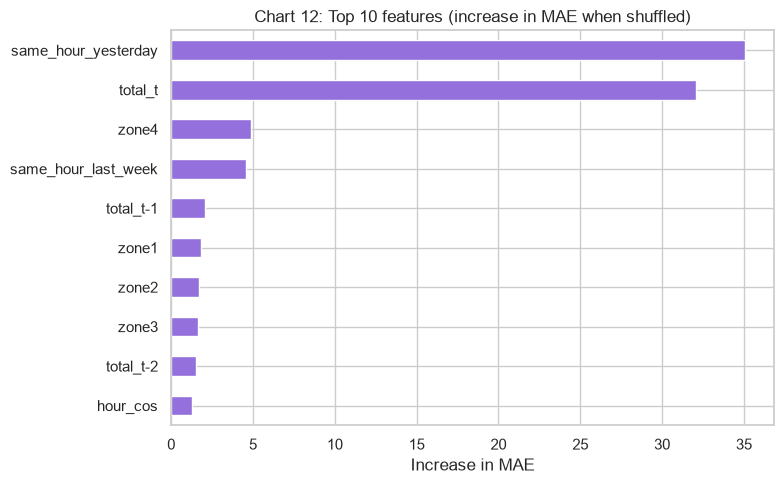

same_hour_yesterday    35.081
total_t                32.046
zone4                   4.864
same_hour_last_week     4.601
total_t-1               2.084
zone1                   1.802
zone2                   1.715
zone3                   1.645
total_t-2               1.497
hour_cos                1.263


In [35]:
# Chart 12: permutation importance of the best model on the test set
pi = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                            scoring="neg_mean_absolute_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
imp.head(10)[::-1].plot.barh(ax=ax, color="mediumpurple")
ax.set_title("Chart 12: Top 10 features (increase in MAE when shuffled)")
ax.set_xlabel("Increase in MAE")
plt.tight_layout(); plt.show()
print(imp.head(10).round(3).to_string())

### Conclusions and limitations

**Answers to the questions**
1. **Patterns.** Consumption has a strong daily cycle (lowest around 4 a.m., peak around 9 p.m.), a clear seasonal swing (about 519 in July 2023 to 645 in November 2023 on average), and only a weak weekday effect.
2. **Models versus baselines.** On the unseen test period (20 January to 23 May 2024) the tuned **Random Forest** was best by MAE (16.5, MAPE 3.0%, R² 0.946). Histogram Gradient Boosting was almost identical (MAE 17.0, slightly lower RMSE 28.8 versus 29.1), so the two are effectively tied. Ridge regression was clearly weaker (MAE 21.0). The baselines were much worse: same hour yesterday MAE 25.9 and persistence MAE 46.0. The Random Forest lowers MAE by about 64% versus persistence and about 36% versus the seasonal-naive baseline.
3. **Important features.** The two most important features by far were the total at the same hour yesterday and the current hourly total; the other features each contribute much less. This agrees with the autocorrelation chart in the EDA.

**Error behaviour.** Residuals are centred near zero (mean -0.2, standard deviation about 29), so the model is not systematically biased. Errors are smallest in the early morning (MAE about 9.6 for the 4 a.m. hour) and largest in the middle of the day (about 27 for 2 p.m.), when demand changes faster and is less regular.

**Limitations**
* Only one city and one chronological split were evaluated; the test period covers January to May only, so summer and autumn performance is not measured.
* No weather, holiday or Ramadan information is available, although these probably drive some of the remaining error.
* Rows with zero readings were treated as outages and filled or removed, and the unit of the data is not documented.
* The task is a one-hour-ahead forecast; longer horizons will be harder.

**Possible extensions:** add weather and calendar-event features, forecast several hours or a day ahead, test on the other sheets (Boujdour, Foum eloued, Marrakech), and compare with dedicated time-series models.